In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("XAU_15m_data.csv", sep=";")   # خواندن دیتای طلا با تایم‌فریم 15 دقیقه

df['Date'] = pd.to_datetime(df['Date'])        # تبدیل ستون تاریخ به نوع datetime
df = df.sort_values('Date').reset_index(drop=True)  

for c in ['Open', 'High', 'Low', 'Close']:     # پیمایش ستون‌های قیمتی
    df[c] = df[c].astype(float)                # تبدیل قیمت‌ها به float

df.head()                                 


,Date,Open,High,Low,Close,Volume
0,2004-06-11 07:15:00,384.0,384.3,383.8,384.3,12
1,2004-06-11 07:30:00,383.8,384.3,383.6,383.8,12
2,2004-06-11 07:45:00,383.3,383.8,383.3,383.8,20
3,2004-06-11 08:00:00,383.8,384.1,383.6,383.6,8
4,2004-06-11 08:15:00,383.6,384.3,383.5,383.5,20


In [ ]:
ATR_PERIOD = 14                                   # تعداد کندل‌ها برای محاسبه‌ی میانگین رایجِ نوسان

high = df['High']                                 # ستون قیمت‌های 

low = df['Low']                                   # ستون قیمت‌های Low
close = df['Close']                               # قیمت‌های پایانی
prev_close = close.shift(1)                       # قیمت پایانی کندل قبلی برای اختلاف

tr = pd.concat([                                  # محاسبه True Range (سه حالت ممکن برای نوسان)
    high - low,                                   # دامنه داخل کندل
    (high - prev_close).abs(),                    # فاصله بین سقف فعلی و بسته‌شدن قبلی
    (low - prev_close).abs()                      # فاصله بین کف فعلی و بسته‌شدن قبلی
], axis=1).max(axis=1)                            # انتخاب بیشترین مقدار از هر سه حالت

df['ATR'] = tr.rolling(ATR_PERIOD).mean()         # محاسبه میانگین متحرک True Range برای دوره مشخص


In [5]:
L, R = 3, 3                           # تعداد کندل‌های چپ و راست برای تشخیص سویینگ
p1 = np.zeros(len(df), dtype=bool)   # آرایه بولی برای علامت‌گذاری P1

for i in range(L, len(df) - R):       # پیمایش دیتافریم (با لحاظ آینده)
    if df['High'][i] == df['High'][i-L:i+R+1].max():  # آیا بیشترین High است؟
        p1[i] = True                  # این نقطه یک Swing High است

df['P1'] = p1                         # افزودن ستون P1 به دیتافریم


: منطق این سلول
این بخش نقاطی را پیدا می‌کند که قله‌ی محلی هستند (Peak).
هر قله‌ی معتبر، یعنی جایی که احتمال برگشت قیمت زیاد است.
این نقاط مبنا برای محاسبه‌ی α* و ورود به معاملهٔ Short هستند.


In [4]:
upper_wick = df['High'] - df[['Open', 'Close']].max(axis=1)  # سایه بالایی کندل
df['Exhaustion'] = upper_wick / df['ATR']                   # نرمال‌سازی با ATR


منطق این سلول
این معیار نشان می‌دهد قدرت خریداران کاهش یافته.
وقتی سایه بالایی بلند شود یعنی قیمت به سقف رفته ولی نتوانسته آن را حفظ کند → نشانه Exhaustion.
در فیلترهای ورودی از این برای تشخیص ضعف خریداران استفاده می‌شود.



In [6]:
LOOKAHEAD = 48                                # چند کندل آینده برای ارزیابی حرکت واقعی
MAX_ALPHA = 5.0                               # بیشترین مقدار مجاز α* (برای جلوگیری از outlier)

alpha_star = np.full(len(df), np.nan)         # آرایه‌ی α* پر از NaN ساخته می‌شود

for i in np.where(df['P1'])[0]:               # فقط روی نقاط قله‌ی P1 loop زده می‌شود
    if i + LOOKAHEAD >= len(df):              # اگر کندل‌های آینده کافی نیست، رد شود
        continue
    if np.isnan(df['ATR'][i]):                # اگر ATR معتبر نیست، رد شود
        continue

    future_low = df['Low'][i+1:i+LOOKAHEAD+1].min()       # کمترین Low آینده تا 48 کندل جلوتر
    raw_alpha = (df['High'][i] - future_low) / df['ATR'][i]   # فرمول اصلی محاسبه α*
    alpha_star[i] = min(raw_alpha, MAX_ALPHA)              # Clamp کردن بیش از حد بزرگ‌ها

df['alpha_star'] = alpha_star                # ثبت α* در دیتافریم


:منطق این سلول
α* قدرت حرکت واقعی بازار بعد از هر قله را می‌سنجد.
اگر بازار خیلی ریورز کند، α* بزرگ‌تر می‌شود.
با محدود کردن (Clamp) تا ۵، از تأثیر نقاط نادر جلوگیری می‌شود.
در واقع این سلول «زمین واقعیت» است و مدل ما تمرکز روی همین شاخص دارد.

In [8]:
ALPHA_TRADE = 0.7          # درصد فاصله از سقف برای ورود Short
SL_ATR = 1.0               # استاپ‌لاس بر اساس 1 ATR
TP_ATR = 1.0               # تارگت معادل 1 ATR
HORIZON = 48               # حداکثر مدت نگهداری معامله (48 کندل)

results = []             
equity = [1.0]            

for i in np.where(
    (df['P1']) &                   # باید قله باشد
    (df['alpha_star'] >= 1.0) &    # باید حرکت کافی بعد از سقف ایجاد شده باشد
    (df['Exhaustion'] >= 0.6)      # کندل با خستگی قوی در سقف
)[0]:

    if i + HORIZON >= len(df):     # اگر آینده کافی نیست، رد شود
        continue

    atr = df['ATR'][i]
    if np.isnan(atr):              # اطمینان از معتبر بودن ATR
        continue

    P1 = df['High'][i]             # سقف فعلی (نقطه ورود مرجع)

    entry = P1 - ALPHA_TRADE * atr # ورود به معامله کوتاه (Sell)
    stop = entry + SL_ATR * atr    # قرار دادن استاپ‌لاس
    target = entry - TP_ATR * atr  # قرار دادن تارگت مساوی با 1R سود

    trade_open = False             # وضعیت معامله بسته/باز

    for j in range(i + 1, i + HORIZON):   # بررسی کندل‌های آینده تا افق تعیین‌شده
        hi = df['High'][j]
        lo = df['Low'][j]

        if not trade_open:                # اگر معامله هنوز باز نشده
            if lo <= entry <= hi:         # بررسی عبور قیمت از نقطه‌ی ورود
                trade_open = True         # ورود انجام شد
        else:
            if hi >= stop:                # برخورد به استاپ‌لاس
                results.append(-1)        # ثبت باخت
                equity.append(equity[-1] - 1)
                break
            if lo <= target:              # برخورد به تارگت
                results.append(1)         # ثبت برد
                equity.append(equity[-1] + 1)
                break


منطقش این‌طوریه:

فقط در قله‌های معتبر و خسته بازار وارد فروش (Short) می‌شود؛
فاصله‌ی ورود و خروج‌ها با ATR سنجیده می‌شود؛
هر معامله یا با برد (تارگت) بسته می‌شود یا با باخت (استاپ).
نتیجه: مقدار مثبت یا منفی به Equity اضافه می‌شود.

In [9]:
results = np.array(results)                 

total_trades = len(results)                    # تعداد کل معاملات
wins = np.sum(results == 1)                   # تعداد بردها
losses = np.sum(results == -1)                # تعداد باخت‌ها
win_rate = wins / total_trades if total_trades > 0 else 0  # نرخ برد

print("Total Trades:", total_trades)         
print("Wins:", wins)                         
print("Losses:", losses)                    
print("Win Rate:", round(win_rate * 100, 2), "%")  


Total Trades: 12878
Wins: 9301
Losses: 3577
Win Rate: 72.22 %


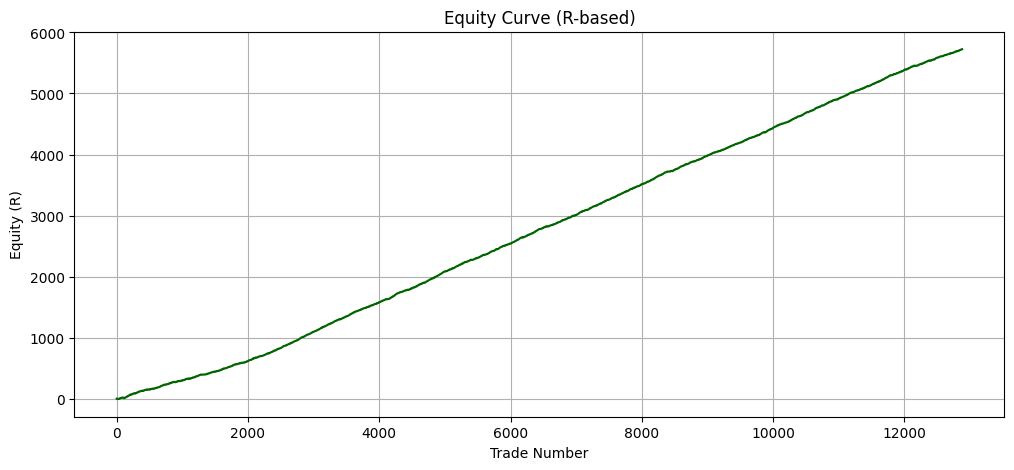

In [10]:
plt.figure(figsize=(12,5))
plt.plot(equity, color='darkgreen')
plt.title("Equity Curve (R-based)")
plt.xlabel("Trade Number")
plt.ylabel("Equity (R)")
plt.grid(True)
plt.show()
